# Project 1: Centrality Measures by Group in Zachary's Karate Club Network

## 1. Introduction

In this project I examine whether node centrality differs across a categorical node attribute in a social network. I use Zachary's karate club network (Zachary, 1977), which records friendship ties among 34 members of a university karate club. Each node carries a categorical attribute, `club`, indicating which of the two factions (`Mr. Hi` or `Officer`) the member joined after the club split.

For every node I compute degree centrality and eigenvector centrality, and I compare both measures between the two factions.

**Hypotheses.** H0: the distribution of centrality is the same in both factions. H1: it differs. Significance level: α = 0.05.

## 2. Data

In [1]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

G = nx.karate_club_graph()

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Connected:", nx.is_connected(G))

Nodes: 34
Edges: 78
Connected: True


The network is connected, so eigenvector centrality is well defined for every node.

## 3. Centrality measures

- **Degree centrality**: the fraction of other nodes a node is directly connected to.
- **Eigenvector centrality**: a node's score is proportional to the sum of its neighbors' scores, so a node is central if it is connected to other central nodes.

In [2]:
deg = nx.degree_centrality(G)
eig = nx.eigenvector_centrality(G, max_iter=1000)
club = nx.get_node_attributes(G, "club")

df = pd.DataFrame({"club": club, "deg": deg, "eig": eig})
df.index.name = "node"
df.head(10)

,club,deg,eig
node,,,
0,Mr. Hi,0.484848,0.355483
1,Mr. Hi,0.272727,0.265954
2,Mr. Hi,0.303030,0.317189
3,Mr. Hi,0.181818,0.211174
4,Mr. Hi,0.090909,0.075966
5,Mr. Hi,0.121212,0.079481
6,Mr. Hi,0.121212,0.079481
7,Mr. Hi,0.121212,0.170955
8,Mr. Hi,0.151515,0.227405


In [3]:
df["club"].value_counts()

club
Mr. Hi     17
Officer    17
Name: count, dtype: int64

## 4. Results
### 4.1 Descriptive statistics

In [4]:
df.groupby("club")[["deg", "eig"]].agg(["count", "mean", "median", "std"]).round(3)

deg                        eig                     
        count   mean median    std count   mean median    std
club                                                         
Mr. Hi     17  0.144  0.121  0.115    17  0.152  0.092  0.099
Officer    17  0.134  0.091  0.124    17  0.141  0.103  0.084

### 4.2 Distributions by group

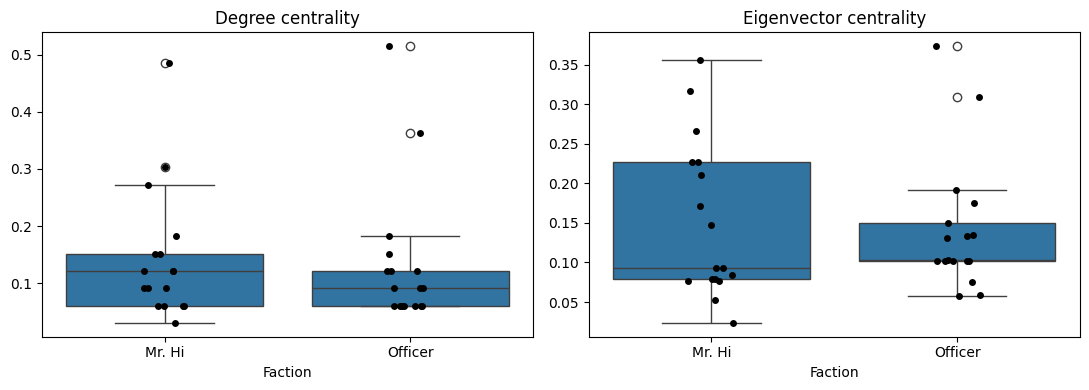

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, metric, title in zip(axes, ["deg", "eig"],
                             ["Degree centrality", "Eigenvector centrality"]):
    sns.boxplot(data=df, x="club", y=metric, ax=ax)
    sns.stripplot(data=df, x="club", y=metric, color="black", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Faction")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

### 4.3 Statistical tests

I first assess normality within each group with the Shapiro-Wilk test. Because centrality distributions in networks are typically right-skewed, I report the Mann-Whitney U test as the primary test and Welch's t-test for comparison.

In [6]:
a = df[df["club"] == "Mr. Hi"]
b = df[df["club"] == "Officer"]

rows = []
for metric in ["deg", "eig"]:
    x, y = a[metric], b[metric]
    rows.append({
        "measure": metric,
        "shapiro_p (Mr. Hi)": stats.shapiro(x).pvalue,
        "shapiro_p (Officer)": stats.shapiro(y).pvalue,
        "welch_t": stats.ttest_ind(x, y, equal_var=False).statistic,
        "welch_p": stats.ttest_ind(x, y, equal_var=False).pvalue,
        "mannwhitney_U": stats.mannwhitneyu(x, y).statistic,
        "mannwhitney_p": stats.mannwhitneyu(x, y).pvalue,
    })

pd.DataFrame(rows).set_index("measure").round(3)

,shapiro_p (Mr. Hi),shapiro_p (Officer),welch_t,welch_p,mannwhitney_U,mannwhitney_p
measure,,,,,,
deg,0.001,0.000,0.262,0.795,161.5,0.561
eig,0.060,0.001,0.336,0.739,138.0,0.836


### 4.4 Most central nodes

In [7]:
df.sort_values("deg", ascending=False).head(5).round(3)

,club,deg,eig
node,,,
33,Officer,0.515,0.373
0,Mr. Hi,0.485,0.355
32,Officer,0.364,0.309
2,Mr. Hi,0.303,0.317
1,Mr. Hi,0.273,0.266


In [8]:
df.sort_values("eig", ascending=False).head(5).round(3)

,club,deg,eig
node,,,
33,Officer,0.515,0.373
0,Mr. Hi,0.485,0.355
2,Mr. Hi,0.303,0.317
32,Officer,0.364,0.309
1,Mr. Hi,0.273,0.266


### 4.5 Relationship between the two measures

In [9]:
df[["deg", "eig"]].corr(method="spearman").round(3)

,deg,eig
deg,1.000,0.777
eig,0.777,1.000


## 5. Discussion

I find no statistically significant difference in either centrality measure between the two factions. Mean degree centrality is 0.144 for `Mr. Hi` and 0.134 for `Officer`; mean eigenvector centrality is 0.152 and 0.141, respectively. All p-values are well above 0.05 (Mann-Whitney: 0.56 for degree, 0.84 for eigenvector; Welch: 0.80 and 0.74), so I fail to reject H0.

The result is explained by the structure of the network. Each faction is anchored by one dominant hub: node 0 (the instructor) in `Mr. Hi` and node 33 (the club administrator) in `Officer`. These two nodes rank first and second on both measures, while the remaining members of both factions have similar, low centrality. The distributions are right-skewed (the Shapiro-Wilk test rejects normality in most groups), which is why the rank-based test is the more appropriate one; both tests lead to the same conclusion.

The two measures are strongly but not perfectly related (Spearman ρ ≈ 0.78). They agree on the top hubs but rank some intermediate nodes differently: for example, node 2 outranks node 32 on eigenvector centrality despite having fewer connections, because its neighbors are themselves well connected.

## 6. Limitations

- The sample is small (17 nodes per group), so the tests have limited power to detect modest differences.
- Network observations are not independent, whereas the tests assume independence; p-values should therefore be interpreted as descriptive.
- The `club` attribute records the outcome of the split, not the group structure before it.

## References

Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452-473. Data loaded via `networkx.karate_club_graph()`.